# **Sistem Rekomendasi Film Berbasis Genre dengan Content-Based Filtering**
Name  : Fakhira Lahen Siregar <br>
ID : MC009D5X2078 <br>



**Sumber Dataset** : https://grouplens.org/datasets/movielens/ <br>

**Informasi Dataset** :
MovieLens 100K adalah kumpulan data film berukuran sedang yang banyak digunakan untuk penelitian sistem rekomendasi. Dataset ini terdiri dari 100.000 rating yang diberikan oleh pengguna terhadap film, dan sangat cocok untuk eksperimen awal dalam collaborative filtering maupun content-based filtering.

**Deskripsi file dan kolom dalam file MovieLens 100K Dataset**:
- File u.data (Rating data)

  Setiap baris merepresentasikan satu rating dari satu user terhadap satu film. Dengan total ada 100.000 baris. Dengan kolom user_id, item_id, rating, timestamp.

  - isi baris pertama u.data:<br>
    <pre>196	242	3	881250949</pre>

- File u.item (Movie metadata)

  Setiap baris memuat informasi 1 film (ID, judul, tanggal rilis, rating di imdb, dan  kode biner genre) dengan total ada 1.682 film.

  - isi baris pertama u.item:  
  <pre>1|Toy Story (1995)|01-Jan-1995||http//us.imdb.com/M/title-exact?Toy%20Story%20(1995)|0|0|0|1|1|1|0|0|0|0|0|0|0|0|0|0|0|0|0</pre>


- File u.user (User metadata)

  Berisikan informasi dari 943 user yang memberikan rating kepada film dengan kolom user_id, age, gender, occupation, dan zip code.

  - isi baris pertama u.user: <br>
  <pre>1|24|M|technician|85711</pre>

- File u.genre

  Berisi nama genre dan ID-nya.

  - isi baris pertama u.genre:<br>
  <pre>unknown|0</pre>

## **Data Collecting**
1. Import library untuk Manipulasi Data dan Data Preprosessing
2. Download dataset dan unzip file
3. Membaca file dan buat dataframe ratings dan movies
4. Menggabungkan dataframe ratings dan movies


In [1]:
import random

# import library manipulasi data (pandas, numpy, matplotlib, seaborn)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# import library data preprosessing (label encode, train_test_split, standardscaler)
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample

# import library pemodelan
from sklearn.metrics.pairwise import cosine_similarity

### Download dataset dan unzip file

In [2]:
# download dataset langsung dari grouplens
!wget https://files.grouplens.org/datasets/movielens/ml-100k.zip

--2025-06-03 10:12:37--  https://files.grouplens.org/datasets/movielens/ml-100k.zip
Resolving files.grouplens.org (files.grouplens.org)... 128.101.65.152
Connecting to files.grouplens.org (files.grouplens.org)|128.101.65.152|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4924029 (4.7M) [application/zip]
Saving to: ‘ml-100k.zip’

ml-100k.zip         100%[===================>]   4.70M  11.2MB/s    in 0.4s    

2025-06-03 10:12:37 (11.2 MB/s) - ‘ml-100k.zip’ saved [4924029/4924029]



In [3]:
# unzip dataset yang sudah di download
!unzip ml-100k.zip

Archive:  ml-100k.zip
   creating: ml-100k/
  inflating: ml-100k/allbut.pl       
  inflating: ml-100k/mku.sh          
  inflating: ml-100k/README          
  inflating: ml-100k/u.data          
  inflating: ml-100k/u.genre         
  inflating: ml-100k/u.info          
  inflating: ml-100k/u.item          
  inflating: ml-100k/u.occupation    
  inflating: ml-100k/u.user          
  inflating: ml-100k/u1.base         
  inflating: ml-100k/u1.test         
  inflating: ml-100k/u2.base         
  inflating: ml-100k/u2.test         
  inflating: ml-100k/u3.base         
  inflating: ml-100k/u3.test         
  inflating: ml-100k/u4.base         
  inflating: ml-100k/u4.test         
  inflating: ml-100k/u5.base         
  inflating: ml-100k/u5.test         
  inflating: ml-100k/ua.base         
  inflating: ml-100k/ua.test         
  inflating: ml-100k/ub.base         
  inflating: ml-100k/ub.test         


### Membaca file dan buat dataframe ratings dan movies

In [4]:
# membaca file csv dengan ratings yang hanya berisi kolom user_id, item_id, rating, timestamp
ratings = pd.read_csv("ml-100k/u.data", sep="\t", names=["user_id", "item_id", "rating", "timestamp"])

In [5]:
# isi dataframe ratings
ratings

,user_id,item_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596
...,...,...,...,...
99995,880,476,3,880175444
99996,716,204,5,879795543
99997,276,1090,1,874795795
99998,13,225,2,882399156


In [6]:
# membuat genre list dari u.genre
genre_labels = [
    'unknown', 'Action', 'Adventure', 'Animation', "Children's", 'Comedy', 'Crime',
    'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical',
    'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western'
]

# membuat label pada kolom movies untuk file u.item (24 kolom)
columns = ['movie_id', 'title', 'release_date', 'video_release_date', 'IMDb_URL'] + genre_labels

In [7]:
# membaca file csv dengan movies yang hanya berisi kolom 'movie_id', 'title', 'release_date', 'video_release_date', 'IMDb_URL', dan genre_labels
movies = pd.read_csv('ml-100k/u.item', sep='|', encoding='latin-1', names=columns, usecols=range(24))

In [8]:
# isi dataframe movies
movies

,movie_id,title,release_date,video_release_date,IMDb_URL,unknown,Action,Adventure,Animation,Children's,...,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
1,2,GoldenEye (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?GoldenEye%20(...,0,1,1,0,0,...,0,0,0,0,0,0,0,1,0,0
2,3,Four Rooms (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Four%20Rooms%...,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,4,Get Shorty (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Get%20Shorty%...,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,Copycat (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Copycat%20(1995),0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1677,1678,Mat' i syn (1997),06-Feb-1998,NaN,http://us.imdb.com/M/title-exact?Mat%27+i+syn+...,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1678,1679,B. Monkey (1998),06-Feb-1998,NaN,http://us.imdb.com/M/title-exact?B%2E+Monkey+(...,0,0,0,0,0,...,0,0,0,0,0,1,0,1,0,0
1679,1680,Sliding Doors (1998),01-Jan-1998,NaN,http://us.imdb.com/Title?Sliding+Doors+(1998),0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
1680,1681,You So Crazy (1994),01-Jan-1994,NaN,http://us.imdb.com/M/title-exact?You%20So%20Cr...,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [9]:
# menghapus kolom release_date, video_release_date, dan IMDb_URL dan unknown dari dataframe movies
movies = movies.drop(['release_date', 'video_release_date', 'IMDb_URL', 'unknown'], axis=1)

In [10]:
# mengubah nama kolom movie_id menjadi item_id
movies.rename(columns={'movie_id': 'item_id'}, inplace=True)

In [11]:
movies.columns

Index(['item_id', 'title', 'Action', 'Adventure', 'Animation', 'Children's',
       'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir',
       'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War',
       'Western'],
      dtype='object')

In [12]:
movies.shape

(1682, 20)

### Menggabungkan dataframe ratings dan movies menjadi df

In [13]:
# menggabungkan data dalam ratings dan movies menjadi df dan disesuaikan dengan item_id nya
df = pd.merge(ratings, movies, on="item_id")

In [14]:
# menampilkan 5 data pertama
df.head()

,user_id,item_id,rating,timestamp,title,Action,Adventure,Animation,Children's,Comedy,...,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,196,242,3,881250949,Kolya (1996),0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,186,302,3,891717742,L.A. Confidential (1997),0,0,0,0,0,...,0,1,0,0,1,0,0,1,0,0
2,22,377,1,878887116,Heavyweights (1994),0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
3,244,51,2,880606923,Legends of the Fall (1994),0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,1
4,166,346,1,886397596,Jackie Brown (1997),0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### **Data Insight** :
- Dataset berhasil didownload langsung dari link GroupLens dan file nya juga berhasil diunzip
- Dataset berhasil dibaca menggunakan fungsi read_csv dan disimpan kedalam variabel ratings (untuk file u.data) dan movies (untuk file u.item)
- Menggabungkan dataframe ratings dan movies dan dibaca kedalam dataframe df

Note : Penggabungan kedua dataframe (ratings 4 kolom dan movies 20 kolom) di sesuaikan dengan item_id. Tujuan nya untuk setiap rating yang diberikan oleh user bisa dikaitkan langsung dengan judul film yang diberi rating tersebut.
Jadi pada hasil penggabungan akan menghasilkan 23 kolom.

## **Data Exploring**
1. Menilai Data (data assesing) dengan:
  - df.info()
  - df.shape
  - df.select_dtypes
  - df.describe()
  - df.columns
  - df.nunique()
2. Melihat hubungan antara item_id dan title
3. Melihat distribusi rating dan visualisasinya
4. Melihat film yang paling banyak dirating (title dan rating)
5. Memvisualisasikan distribusi genre
5. Melihat korelasi kolom dengan heatmap

### Assesing Data

In [15]:
# menampilkan informasi dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 23 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   user_id      100000 non-null  int64 
 1   item_id      100000 non-null  int64 
 2   rating       100000 non-null  int64 
 3   timestamp    100000 non-null  int64 
 4   title        100000 non-null  object
 5   Action       100000 non-null  int64 
 6   Adventure    100000 non-null  int64 
 7   Animation    100000 non-null  int64 
 8   Children's   100000 non-null  int64 
 9   Comedy       100000 non-null  int64 
 10  Crime        100000 non-null  int64 
 11  Documentary  100000 non-null  int64 
 12  Drama        100000 non-null  int64 
 13  Fantasy      100000 non-null  int64 
 14  Film-Noir    100000 non-null  int64 
 15  Horror       100000 non-null  int64 
 16  Musical      100000 non-null  int64 
 17  Mystery      100000 non-null  int64 
 18  Romance      100000 non-null  int64 
 19  Sci

In [16]:
# mengubah tipe data kolom timestamp menjadi datetime
df['timestamp'] = pd.to_datetime(df['timestamp'], unit='s')
print('Tipe data kolom timestamp berhasil di ubah menjadi timestamp')

Tipe data kolom timestamp berhasil di ubah menjadi timestamp


In [17]:
# menampilkan banyak baris dan banyak kolom
baris, kolom = df.shape
print(f"Jumlah baris: {baris}")
print(f"Jumlah kolom: {kolom}")

Jumlah baris: 100000
Jumlah kolom: 23


In [18]:
# menghitung kolom dengan tipe data numerik
numeric_cols = df.select_dtypes(include='number').columns
print(f"Jumlah kolom numerik: {len(numeric_cols)}")

Jumlah kolom numerik: 21


In [19]:
# menghitung kolom dengan tipe data kategorikal
categorical_cols = df.select_dtypes(include='object').columns
print(f"Jumlah kolom kategorikal: {len(categorical_cols)}")

Jumlah kolom kategorikal: 1


In [20]:
# menampilkan deskripsi atau nilai agregasi dari df
df.describe()

,user_id,item_id,rating,timestamp,Action,Adventure,Animation,Children's,Comedy,Crime,...,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
count,100000.00000,100000.000000,100000.000000,100000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.00000,100000.000000,100000.000000
mean,462.48475,425.530130,3.529860,1997-12-31 00:40:51.488619904,0.255890,0.137530,0.036050,0.071820,0.298320,0.080550,...,0.013520,0.017330,0.053170,0.049540,0.052450,0.194610,0.12730,0.21872,0.093980,0.018540
min,1.00000,1.000000,1.000000,1997-09-20 03:05:10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000
25%,254.00000,175.000000,3.000000,1997-11-13 19:18:29.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000
50%,447.00000,322.000000,4.000000,1997-12-22 21:42:24,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000
75%,682.00000,631.000000,4.000000,1998-02-23 18:53:04,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000
max,943.00000,1682.000000,5.000000,1998-04-22 23:10:38,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.00000,1.000000,1.000000
std,266.61442,330.798356,1.125674,NaN,0.436362,0.344408,0.186416,0.258191,0.457523,0.272144,...,0.115487,0.130498,0.224373,0.216994,0.222934,0.395902,0.33331,0.41338,0.291802,0.134894


In [21]:
# menampilkan banyaj nilai unik dari tiap kolom
columns = df.columns
for col in df.columns:
    nunique_values = df[col].nunique()
    print(f"Banyak nilai unik di kolom '{col}': {nunique_values}\n")

Banyak nilai unik di kolom 'user_id': 943

Banyak nilai unik di kolom 'item_id': 1682

Banyak nilai unik di kolom 'rating': 5

Banyak nilai unik di kolom 'timestamp': 49282

Banyak nilai unik di kolom 'title': 1664

Banyak nilai unik di kolom 'Action': 2

Banyak nilai unik di kolom 'Adventure': 2

Banyak nilai unik di kolom 'Animation': 2

Banyak nilai unik di kolom 'Children's': 2

Banyak nilai unik di kolom 'Comedy': 2

Banyak nilai unik di kolom 'Crime': 2

Banyak nilai unik di kolom 'Documentary': 2

Banyak nilai unik di kolom 'Drama': 2

Banyak nilai unik di kolom 'Fantasy': 2

Banyak nilai unik di kolom 'Film-Noir': 2

Banyak nilai unik di kolom 'Horror': 2

Banyak nilai unik di kolom 'Musical': 2

Banyak nilai unik di kolom 'Mystery': 2

Banyak nilai unik di kolom 'Romance': 2

Banyak nilai unik di kolom 'Sci-Fi': 2

Banyak nilai unik di kolom 'Thriller': 2

Banyak nilai unik di kolom 'War': 2

Banyak nilai unik di kolom 'Western': 2



### Hubungan item_id dan title

In [22]:
# melihat data duplikasi title dan item_id
dupe_titles = movies[movies.duplicated(subset=['title'], keep=False)].sort_values('title')
print(dupe_titles[['item_id', 'title']])

      item_id                           title
669       670           Body Snatchers (1993)
572       573           Body Snatchers (1993)
1649     1650         Butcher Boy, The (1998)
1644     1645         Butcher Boy, The (1998)
1233     1234    Chairman of the Board (1998)
1653     1654    Chairman of the Board (1998)
245       246              Chasing Amy (1997)
267       268              Chasing Amy (1997)
1605     1606                 Deceiver (1997)
308       309                 Deceiver (1997)
1256     1257  Designated Mourner, The (1997)
1255     1256  Designated Mourner, The (1997)
347       348       Desperate Measures (1998)
328       329       Desperate Measures (1998)
499       500            Fly Away Home (1996)
303       304            Fly Away Home (1996)
1616     1617                Hugo Pool (1997)
1174     1175                Hugo Pool (1997)
1606     1607        Hurricane Streets (1998)
1394     1395        Hurricane Streets (1998)
304       305           Ice Storm,

**Data Insight:**
- Melihat nilai nunique dilakukan untuk melihat apakah ada data yang dirasa tidak normal. Dan ternyata diidentifikasi item_id dan title memiliki nilai yang berbeda yaitu item_id ada 1682 dan title ada 1664.
- Setelah dilihat hasilnya dengan <pre>[movies.duplicated(subset=['title'], keep=False)]</pre> ditemukan beberapa duplikasi judul film yang sama dengan item_id berbeda.
- Saya memilih untuk menghapus data duplikasi antara title dan item_id karena tidak akan menggagu proses content-based dan collaborative filtering.

### Distribusi rating

In [23]:
# melihat nilai distribusi dari kolom rating
df.rating.value_counts()

,count
rating,
4,34174
3,27145
5,21201
2,11370
1,6110


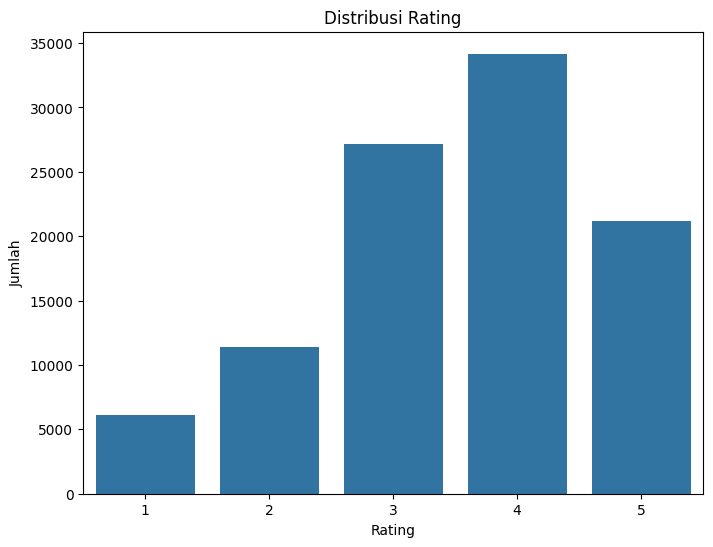

In [24]:
# visualisasi bar chart dari kolom rating
plt.figure(figsize=(8, 6))
sns.countplot(x='rating', data=df)
plt.title('Distribusi Rating')
plt.xlabel('Rating')
plt.ylabel('Jumlah')
plt.show()

**Data Insight**
- Paling banyak orang memberikan rating 4 untuk keseluruhan film
- Hanya 21201 kali rating untuk keseluruhan film

### Film paling banyak di rating

In [25]:
# melihat film apa yang paling sering dirating
top_rating = df['title'].value_counts().head()
top_rating

,count
title,
Star Wars (1977),583
Contact (1997),509
Fargo (1996),508
Return of the Jedi (1983),507
Liar Liar (1997),485


In [26]:
# Film yang paling banyak dirating
filmtop = top_rating.index.tolist()
filmtop

['Star Wars (1977)',
 'Contact (1997)',
 'Fargo (1996)',
 'Return of the Jedi (1983)',
 'Liar Liar (1997)']

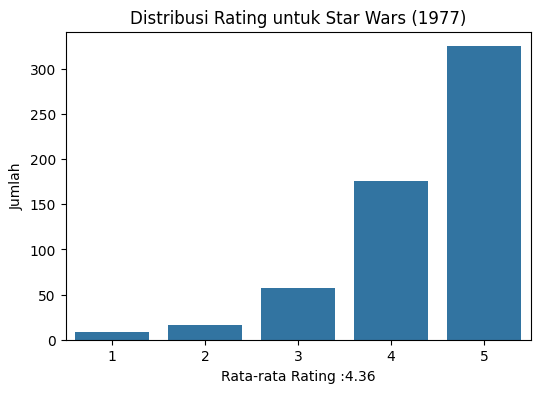

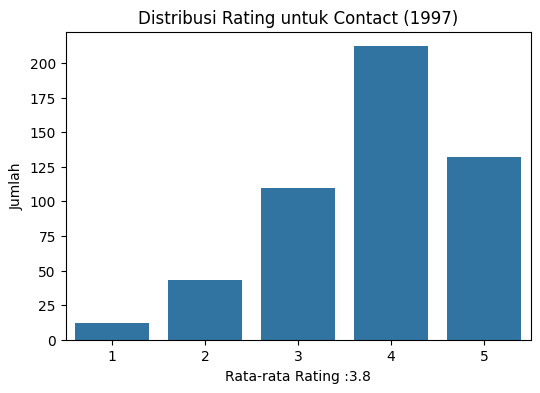

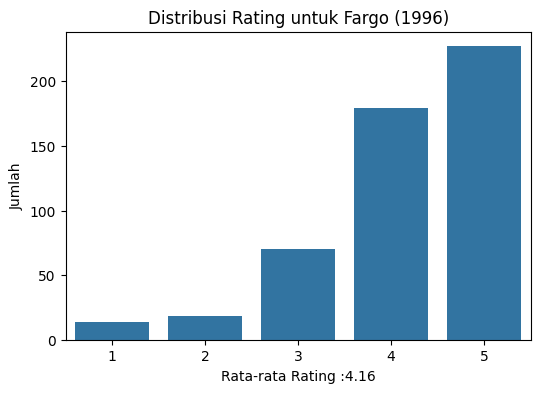

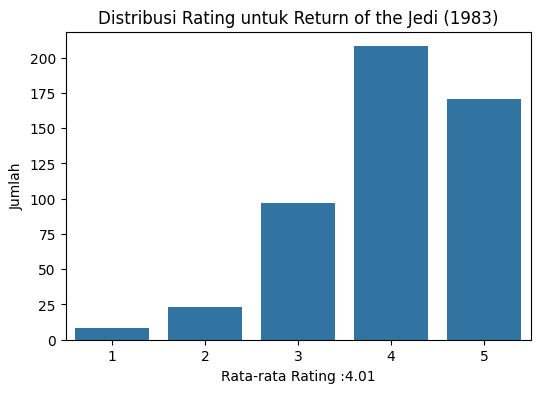

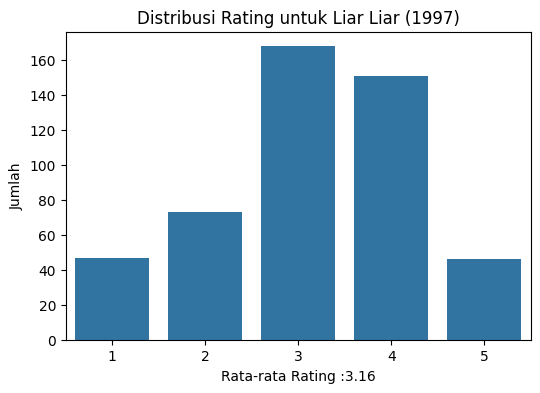

In [27]:
# melihat rating dari filmtop (film yang paling banyak dirating)
for top in filmtop :
    plt.figure(figsize=(6, 4))
    sns.countplot(x='rating', data=df[df['title'] == top])
    plt.title(f'Distribusi Rating untuk {top}')
    meanrating = round(df[df['title'] == top]['rating'].mean(), 2)
    plt.xlabel(f'Rata-rata Rating :{meanrating}')
    plt.ylabel('Jumlah')

**Data Insight :**
- Tidak semua film dengan rating terbanyak adalah film dengan rata-rata rating tertinggi

### Visualisasi distribusi Genre

In [28]:
# hapus unknown dari genre_labels

genre_labels.remove('unknown')
genre_labels

['Action',
 'Adventure',
 'Animation',
 "Children's",
 'Comedy',
 'Crime',
 'Documentary',
 'Drama',
 'Fantasy',
 'Film-Noir',
 'Horror',
 'Musical',
 'Mystery',
 'Romance',
 'Sci-Fi',
 'Thriller',
 'War',
 'Western']

<ipython-input-29-99943d91df16>:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=genre_counts.index, y=genre_counts.values, palette='viridis')


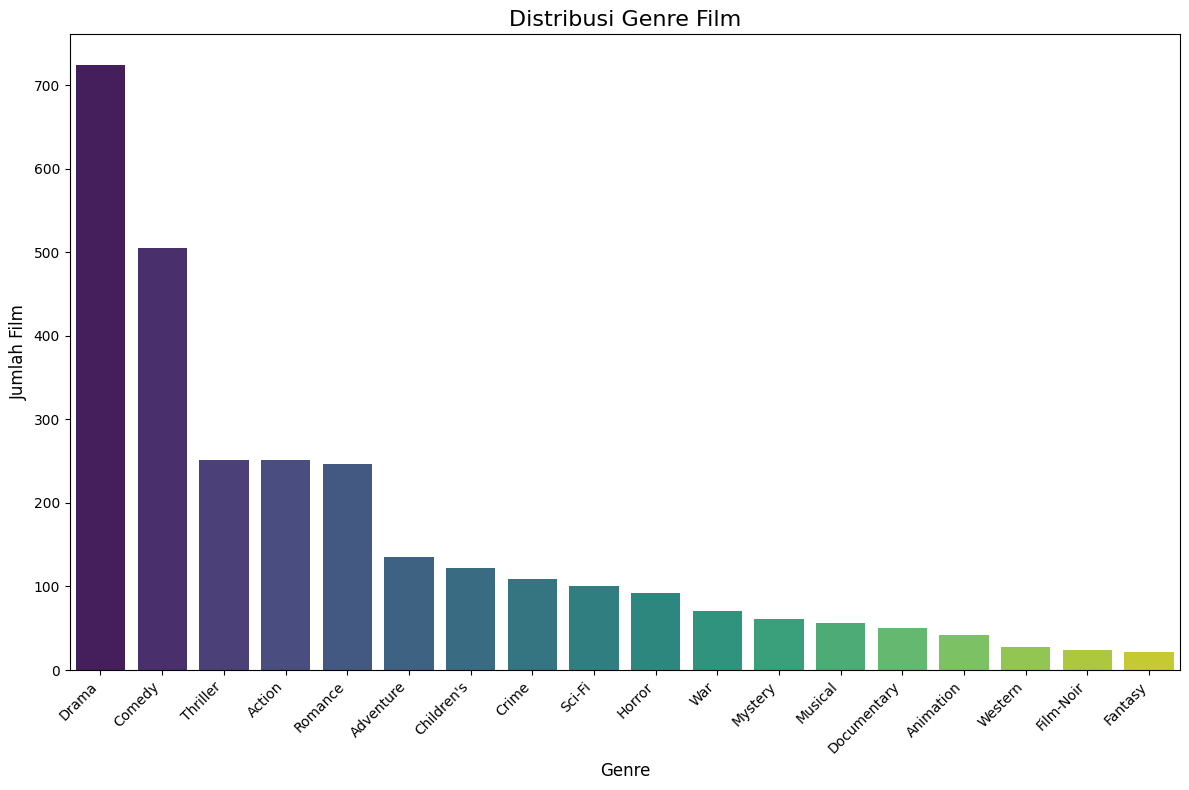

In [29]:
# membuat visualisasi distribusi genre

# menghitung jumlah total film per genre
genre_counts = movies[genre_labels].sum().sort_values(ascending=False)

# visualisasi distribusi genre
plt.figure(figsize=(12, 8))
sns.barplot(x=genre_counts.index, y=genre_counts.values, palette='viridis')
plt.title('Distribusi Genre Film', fontsize=16)
plt.xlabel('Genre', fontsize=12)
plt.ylabel('Jumlah Film', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### Data Insight:
- Visualisasi bar plot menunjukkan jumlah film untuk setiap genre.
- Genre 'Drama' memiliki jumlah film terbanyak, diikuti oleh 'Comedy' dan 'Action'.
- Beberapa genre seperti 'Fantasy','Western', dan 'Film-Noir' memiliki jumlah film yang relatif sedikit.

### Korelasi antar variabel

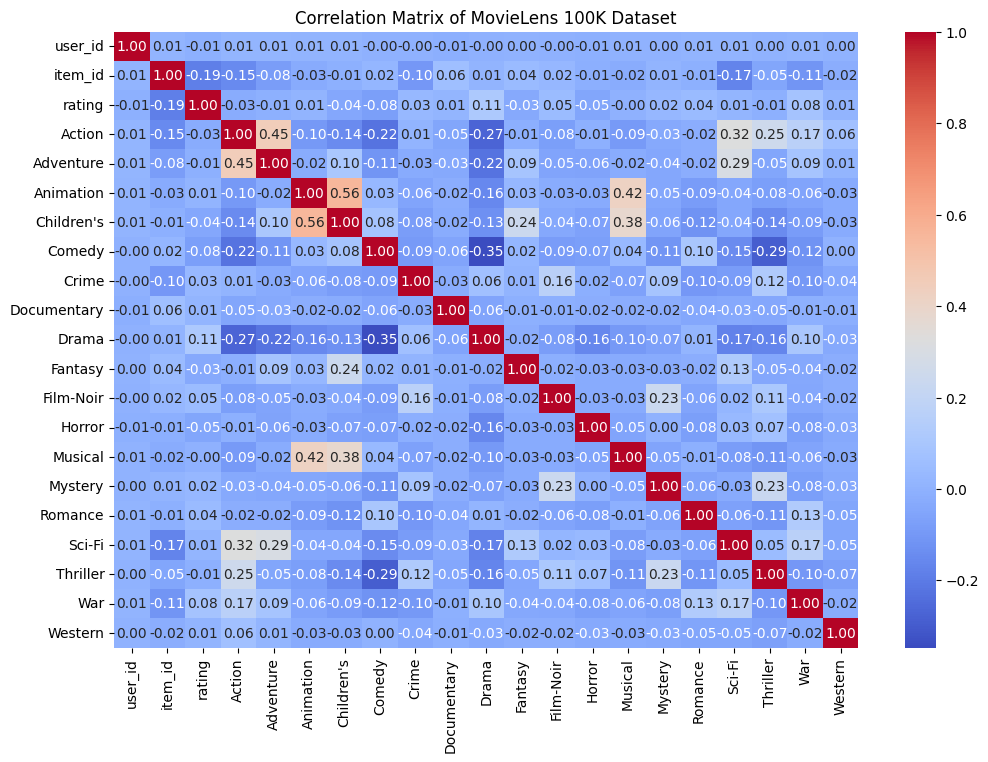

In [30]:
# menampilkan heatmap korelasi dataset df (numeric_only=True)

correlation_matrix = df.corr(numeric_only=True)
# Membuat heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of MovieLens 100K Dataset')
plt.show()

### **Data Insight:**
- Dataset berisi 100.000 baris dan 23 kolom
- Terdapat 21 kolom numerik (user_id, item_id, rating, dan genre_labels), 1 kolom kategorikal (title), dan 1 kolom datetime (timestamp)
- Nilai agregasi normal dan tidak diidentifikasi data abnormal
- Pemberian rata-rata kolom rating ada di 3.5
- Diidentifikasi ada pebedaan banyak nilai unik pada title dan item_id
- Setelah dicek lebih dalam, terdapat baris duplikasi antara title dan item_id. Tapi tidak saya hapus karena tidak akan mengganggu system rekomendasi (akan ada kemungkinan akan ada film yang 2 kali direkomendasikan).
- Setelah dilihat distribusi rating, rating 4 adalah rating yang paling banyak diberikan user untuk keseluruhan film.
- Film yang paling banyak dirating adalah :
 1. 'Star Wars (1977)',
 2. 'Contact (1997)',
 3. 'Fargo (1996)',
 4. 'Return of the Jedi (1983)',
 5. 'Liar Liar (1997)'
- Film yang paling banyak di rating bukan berarti adalah film yang paling tinggi rating nya. Karena Film kedua terbanyak dirating adalah Contact tahun 1997 hanya memiliki rating 3.8
- Setelah pemivisualisasian ditribusi genre :
  - Genre 'Drama' memiliki jumlah film terbanyak, diikuti oleh 'Comedy' dan 'Action'.
  - Beberapa genre seperti 'Fantasy','Western', dan 'Film-Noir' memiliki jumlah film yang relatif sedikit.
- Setelah dilihat korelasi dengan heatmap. Hubungan korelasi antar genre terlihat seperti beberapa film ada yang action, dan adventure sekaligus. Atau film anak-anak biasanya film animation. Dan film Animation biasanya juga bergenre musical.

## Data preparation
1. Memeriksa missing value dan duplikasi data
2. Membuat fitur genre dalam bentuk yang mudah dipakai
3. Membangun item profile (film = baris, genre = kolom)

### Memeriksa missing value dan duplikasi data

In [31]:
# memeriksa apakah ada nilai yang kosong (missing value)
isnul = df.isnull().sum()
print(f"Banyak missing value : \n{isnul}")

Banyak missing value : 
user_id        0
item_id        0
rating         0
timestamp      0
title          0
Action         0
Adventure      0
Animation      0
Children's     0
Comedy         0
Crime          0
Documentary    0
Drama          0
Fantasy        0
Film-Noir      0
Horror         0
Musical        0
Mystery        0
Romance        0
Sci-Fi         0
Thriller       0
War            0
Western        0
dtype: int64


In [32]:
# memeriksa apakah ada baris duplikat
duplikat = df.duplicated().sum()
print(f"Banyak duplikat : {duplikat}")

Banyak duplikat : 0


### Menyusun fitur genre dan film

In [33]:
df.head()

,user_id,item_id,rating,timestamp,title,Action,Adventure,Animation,Children's,Comedy,...,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,196,242,3,1997-12-04 15:55:49,Kolya (1996),0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,186,302,3,1998-04-04 19:22:22,L.A. Confidential (1997),0,0,0,0,0,...,0,1,0,0,1,0,0,1,0,0
2,22,377,1,1997-11-07 07:18:36,Heavyweights (1994),0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
3,244,51,2,1997-11-27 05:02:03,Legends of the Fall (1994),0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,1
4,166,346,1,1998-02-02 05:33:16,Jackie Brown (1997),0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [34]:
# buat genre_cols yang berisikan nama kolom genre
genre_cols = ['Action', 'Adventure', 'Animation', "Children's", 'Comedy', 'Crime', 'Documentary',
              'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance',
              'Sci-Fi', 'Thriller', 'War', 'Western']

### Membangun item profile (film = baris, genre = kolom)

In [35]:
# membuat df movie_features untuk setiap film unik (tanpa duplikasi judul)
movie_features = df[['title'] + genre_cols].drop_duplicates().set_index('title')

In [36]:
# menampilkan hasil df movie_features
movie_features.head()

,Action,Adventure,Animation,Children's,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
title,,,,,,,,,,,,,,,,,,
Kolya (1996),0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
L.A. Confidential (1997),0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,1,0,0
Heavyweights (1994),0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
Legends of the Fall (1994),0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,1
Jackie Brown (1997),0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0


In [37]:
# menampilkan banyak kolom dan baris
movie_features.shape

(1664, 18)

In [38]:
# membuat copyan movie_genres
item_profiles = movie_features.copy()

### Data Insight :
- Dataframe berhasil dibuat menjadi dataframe yang lebih mudah dibaca saat modelling
- Data tidak perlu di onehot encoding lagi karena sebelumnya dataset sudah rapih
- Data tidak perlu melewati tahap tf-idf karena tidak ada fitur teks yang perlu di proses

## Model Development
1. Hitung cosine similirity dan menyimpan hasil nya di consim_sin_df
2. Membuat fungsi recommend_movies dengan parameter title, similarity_df=cosine_sim_df, top_n=5


### Hitung cosine similirity

In [39]:
movie_features

,Action,Adventure,Animation,Children's,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
title,,,,,,,,,,,,,,,,,,
Kolya (1996),0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
L.A. Confidential (1997),0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,1,0,0
Heavyweights (1994),0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
Legends of the Fall (1994),0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,1
Jackie Brown (1997),0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Mamma Roma (1962),0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
"Eighth Day, The (1996)",0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
Girls Town (1996),0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0


In [40]:
# menghitung cosine similarity antar film berdasarkan genre
cosine_sim = cosine_similarity(movie_features)

In [52]:
# mengubah hasil similarity jadi dataframe agar lebih mudah akses
cosine_sim_df = pd.DataFrame(
    cosine_sim,
    index=movie_features.index,   # index berupa judul film
    columns=movie_features.index  # kolom juga berupa judul film
)

In [53]:
# menampilkan dataframe cosime
cosine_sim_df.head()

title,Kolya (1996),L.A. Confidential (1997),Heavyweights (1994),Legends of the Fall (1994),Jackie Brown (1997),Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1963),"Hunt for Red October, The (1990)","Jungle Book, The (1994)",Grease (1978),"Remains of the Day, The (1993)",...,Sleepover (1995),Everest (1998),Nobody Loves Me (Keiner liebt mich) (1994),Getting Away With Murder (1996),Scream of Stone (Schrei aus Stein) (1991),Mamma Roma (1962),"Eighth Day, The (1996)",Girls Town (1996),"Silence of the Palace, The (Saimt el Qusur) (1994)",Dadetown (1995)
title,,,,,,,,,,,,,,,,,,,,,
Kolya (1996),1.000000,0.000000,0.707107,0.000000,0.000000,0.000000,0.000000,0.000000,0.577350,0.000000,...,0.707107,0.0,0.707107,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
L.A. Confidential (1997),0.000000,1.000000,0.000000,0.000000,0.353553,0.000000,0.353553,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
Heavyweights (1994),0.707107,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.408248,0.408248,0.000000,...,0.500000,0.0,0.500000,0.707107,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
Legends of the Fall (1994),0.000000,0.000000,0.000000,1.000000,0.353553,0.353553,0.000000,0.288675,0.288675,0.500000,...,0.353553,0.0,0.353553,0.000000,0.500000,0.500000,0.500000,0.500000,0.500000,0.0
Jackie Brown (1997),0.000000,0.353553,0.000000,0.353553,1.000000,0.000000,0.000000,0.000000,0.000000,0.707107,...,0.500000,0.0,0.500000,0.000000,0.707107,0.707107,0.707107,0.707107,0.707107,0.0


### Membuat fungsi recommend_movies

In [55]:
# Buat fungsi rekomendasi
def recommend_movies(title, similarity_df=cosine_sim_df, top_n=5):
    if title not in similarity_df.columns:
        return f"Film '{title}' tidak ditemukan dalam database."

    # Ambil skor similarity film terhadap semua film
    sim_scores = similarity_df[title].sort_values(ascending=False)

    # Hapus film itu sendiri dari hasil
    sim_scores = sim_scores.drop(title)

    # Ambil top-N film yang paling mirip
    recommended_titles = sim_scores.head(top_n).index.tolist()

    return recommended_titles

In [56]:
# penggunaan fungsi recommend_movies
rekomendasi = recommend_movies("Toy Story (1995)", top_n=5)
print("Rekomendasi film mirip 'Toy Story (1995)':")
for i, film in enumerate(rekomendasi, 1):
    print(f"{i}. {film}")

Rekomendasi film mirip 'Toy Story (1995)':
1. Aladdin and the King of Thieves (1996)
2. Goofy Movie, A (1995)
3. Aladdin (1992)
4. Heavyweights (1994)
5. Beavis and Butt-head Do America (1996)


## Model Evaluasi
1. Mencetak film acak dari movies_features.title
2. Meminta input film yang ingin direkomendasi
3. Menampilkan film rekomendasi berdasarkan nilai input
4. Membuat dataframe yang berisikan kolom title dan genre_list (string)
5. Mencetak genre dari masing-masing film yang sebelumnya ditampilkan untuk direkomendasikan

In [57]:
# mencetak 5 judul film acak
random_titles = random.sample(list(movie_features.index), 5)
print("Contoh judul film (pilih salah satu):")
for i, title in enumerate(random_titles, 1):
    print(f"{i}. {title}")

# menginput judul yang ingin dicari rekomendasian nya
input_title = input("Masukkan salah satu judul film dari daftar di atas: ")

Contoh judul film (pilih salah satu):
1. Nixon (1995)
2. Land and Freedom (Tierra y libertad) (1995)
3. 3 Ninjas: High Noon At Mega Mountain (1998)
4. Palookaville (1996)
5. Switchblade Sisters (1975)
Masukkan salah satu judul film dari daftar di atas: Nixon (1995)


In [58]:
recommendations = recommend_movies(input_title)
print(f"\nRekomendasi untuk '{input_title}':")
for i, rec in enumerate(recommendations, 1):
    print(f"{i}. {rec}")


Rekomendasi untuk 'Nixon (1995)':
1. Shadow of Angels (Schatten der Engel) (1976)
2. Brothers in Trouble (1995)
3. Next Step, The (1995)
4. Sunchaser, The (1996)
5. Scream of Stone (Schrei aus Stein) (1991)


In [59]:
def extract_genres(row):
    return ', '.join([genre for genre in genre_cols if row[genre] == 1])

# Buat DataFrame dengan title dan genre list
movie_genres_df = movie_features.copy()
movie_genres_df['genre_list'] = movie_genres_df.apply(extract_genres, axis=1)
movie_genres_df = movie_genres_df[['genre_list']]

In [60]:
# Tampilkan genre dari film input dan rekomendasi
print(f"Genre dari '{input_title}':")
print(movie_genres_df.loc[input_title, 'genre_list'])

print("\nGenre dari film rekomendasi:")
for title in recommendations:
    print(f"{title}: {movie_genres_df.loc[title, 'genre_list']}")

Genre dari 'Nixon (1995)':
Drama

Genre dari film rekomendasi:
Shadow of Angels (Schatten der Engel) (1976): Drama
Brothers in Trouble (1995): Drama
Next Step, The (1995): Drama
Sunchaser, The (1996): Drama
Scream of Stone (Schrei aus Stein) (1991): Drama


# **Laporan Proyek Machine Learning Terapan - Fakhira Lahen Siregar**

## Project Overview

Pada era digital ini, konsumen memiliki akses ke ribuan film dan serial TV melalui berbagai platform streaming. Tantangan yang muncul adalah bagaimana membantu pengguna menemukan konten yang sesuai dengan preferensi mereka di antara banyaknya pilihan yang tersedia. Oleh karena itu, dibutuhkan sebuah sistem rekomendasi film yang dapat memberikan saran kepada para konsumen berdasarkan preferensi pengguna atau karakteristik film (Content Based Filtering).

MovieLens 100K berisikan dataset sistem rekomendasi yang paling banyak digunakan untuk penelitian dan pembelajaran. Dataset ini berisi data 100.000 rating dari 943 pengguna terhadap 1682 film. Dengan membangun sistem rekomendasi menggunakan pendekatan content-based filtering, proyek ini bertujuan untuk menyarankan film yang serupa dengan film yang pernah disukai pengguna berdasarkan informasi genre.

Referensi:
1. R. Vyshnavi, "Genre Based Movie Recommendation System Using Collaborative Filtering," International Journal of Research Publication and Reviews, vol. 4, no. 12, pp. 4029-4032, Dec. 2023. [Online]. Available: https://ijrpr.com/uploads/V4ISSUE12/IJRPR20642.pdf
   - Penelitian yang dilakukan oleh R. Vyshnavi (2023) mengembangkan sistem rekomendasi film berbasis genre dengan pendekatan collaborative filtering. Dalam penelitian tersebut, data MovieLens digunakan sebagai sumber utama, dan fitur genre dimanfaatkan bersama dengan teknik clustering menggunakan algoritma K-Means untuk mengelompokkan pengguna berdasarkan kesamaan preferensi. Setelah itu, rekomendasi diberikan berdasarkan pengguna lain yang berada dalam klaster yang sama. Evaluasi dilakukan menggunakan metrik precision, recall, dan F1-score. Hasilnya menunjukkan bahwa penambahan fitur genre dapat meningkatkan kualitas rekomendasi karena memberikan hasil yang lebih personal dan relevan.

2. S.-M. Choi, S.-K. Ko, Y.-S. Han, S.-W. Kim, & H.-J. Kim, "A movie recommendation algorithm based on genre correlations," Expert Systems with Applications, vol. 39, no. 9, pp. 8079-8085, Jul. 2012. doi: 10.1016/j.eswa.2012.01.186
   - Penelitian oleh S.-M. Choi dan rekan-rekannya (2012) memfokuskan pada algoritma rekomendasi film dengan memanfaatkan korelasi antar genre. Metode ini bertujuan untuk mengatasi masalah cold-start dan sparsity yang umum terjadi pada sistem collaborative filtering. Dengan mengandalkan korelasi antara genre yang stabil dan tidak berubah-ubah seperti halnya preferensi pengguna, sistem dapat menyarankan film yang tidak hanya memiliki genre identik, tetapi juga genre yang berkaitan erat. Hasil penelitian menunjukkan bahwa pendekatan ini dapat menghasilkan rekomendasi yang lebih akurat dan menyeluruh.

## Business Understanding

### Problem Statements
- Bagaimana membangun sistem rekomendasi film yang dapat menyarankan film berdasarkan genre?
- Bagaimana memanfaatkan data genre untuk menentukan kesamaan antar film?

### Goals
- Mengembangkan sistem rekomendasi berdasarkan genre film.
- Memberikan rekomendasi film serupa berdasarkan input film yang disukai pengguna.

### Solution Statements
- Pendekatan Content-Based Filtering: merekomendasikan film berdasarkan kemiripan fitur konten (genre).
- Pendekatan alternatif (tidak digunakan): Collaborative Filtering yang memanfaatkan kesamaan pola rating antar pengguna.

## Data Understanding

Dataset yang digunakan adalah MovieLens 100K dari GroupLens Research: https://grouplens.org/datasets/movielens/100k/

Dataset ini terdiri dari beberapa file, berikut informasi tentang beberapa file yang digunakan:

- **File u.data (Rating data)**:  
  Setiap baris merepresentasikan satu rating dari satu user terhadap satu film. Total: 100.000 baris.  
  Kolom: user_id, item_id, rating, timestamp.  
  Contoh: `196	242	3	881250949`

- **File u.item (Movie metadata)**:  
  Setiap baris memuat informasi 1 film dengan total 1.682 baris.  
  Termasuk: item_id, title, tanggal rilis, dan kode biner genre.  
  Contoh: `1|Toy Story (1995)|01-Jan-1995|...|0|0|0|1|1|1|...`

- **File u.user (User metadata)**:  
  Informasi dari 943 user yang memberikan rating.  
  Kolom: user_id, age, gender, occupation, zip code.  
  Contoh: `1|24|M|technician|85711`

- **File u.genre**:  
  Daftar nama genre dan ID-nya.  
  Contoh: `unknown|0`

### Penggabungan DataFrame
```
df = pd.merge(ratings, movies, on="item_id")
```
- **ratings**: 100.000 baris, dari `u.data`
- **movies**: 1.682 baris, dari `u.item`
- **df**: hasil gabungan ratings dan movies berdasarkan `item_id` → 100.000 baris dan 23 kolom

Berikut adalah hasil dari penggabungan ratings dan movies menjadi df dengan menampilkan hasil dari `df.head()` :
| user_id | item_id | rating | timestamp | title                  | Action | Adventure | Animation | Children's | Comedy | ... | Fantasy | Film-Noir | Horror | Musical | Mystery | Romance | Sci-Fi | Thriller | War | Western |
|---------|---------|--------|-----------|------------------------|--------|-----------|-----------|------------|--------|-----|---------|-----------|--------|---------|---------|---------|--------|----------|-----|---------|
| 196     | 242     | 3      | 881250949 | Kolya (1996)           | 0      | 0         | 0         | 0          | 1      | ... | 0       | 0         | 0      | 0       | 0       | 0       | 0      | 0        | 0   | 0       |
| 186     | 302     | 3      | 891717742 | L.A. Confidential (1997)| 0      | 0         | 0         | 0          | 0      | ... | 0       | 1         | 0      | 0       | 1       | 0       | 0      | 1        | 0   | 0       |
| 22      | 377     | 1      | 878887116 | Heavyweights (1994)    | 0      | 0         | 0         | 1          | 1      | ... | 0       | 0         | 0      | 0       | 0       | 0       | 0      | 0        | 0   | 0       |
| 244     | 51      | 2      | 880606923 | Legends of the Fall (1994)| 0    | 0         | 0         | 0          | 0      | ... | 0       | 0         | 0      | 0       | 0       | 1       | 0      | 0        | 1   | 1       |
| 166     | 346     | 1      | 886397596 | Jackie Brown (1997)    | 0      | 0         | 0         | 0          | 0      | ... | 0       | 0         | 0      | 0       | 0       | 0       | 0      | 0        | 0   | 0       |


### Insight:
- Dataset berisi 100.000 baris dan 23 kolom
- Awaln
- Terdapat 21 kolom numerik (user_id, item_id, rating, dan genre_labels), 1 kolom kategorikal (title), dan 1 kolom datetime (timestamp)
- Nilai agregasi normal dan tidak diidentifikasi data abnormal
- Pemberian rata-rata kolom rating ada di 3.5
- Diidentifikasi ada pebedaan banyak nilai unik pada title dan item_id
- Setelah dicek lebih dalam, terdapat baris duplikassi antara title dan item_id. Tapi tidak saya hapus karena tidak akan mengganggu system rekomendasi (akan ada kemungkinan akan ada film yang 2 kali direkomendasikan).
- Setelah dilihat distribusi rating, rating 4 adalah rating yang paling banyak diberikan user untuk keseluruhan film.
- Film yang paling banyak dirating adalah :
 1. 'Star Wars (1977)',
 2. 'Contact (1997)',
 3. 'Fargo (1996)',
 4. 'Return of the Jedi (1983)',
 5. 'Liar Liar (1997)'
- Film yang paling banyak diberi rating bukan berarti adalah film yang paling tinggi rating nya. Karena Film kedua terbanyak dirating adalah Contact tahun 1997 hanya memiliki rating 3.8
- Visualisasi ditribusi genre :
   ![Distribusi Genre](https://raw.githubusercontent.com/Lahen194/Project-MovieRecommendation/main/genre.png)
   Dari visualisasi diatas :
   - Grafik menunjukan distribusi rating dengan mengurutkan film dengan genre terbanyak terbanyak hingga tersedikit.
   - Film dengan genre terbanyak adalah genre Drama dengan distribusi diatas 700 dari 934 film.
   - Film dengan genre tersedikit adalah genre Western, Film-Noir, dan Fantasy yaitu dibawah 50 film.
-  Visualisasi heatmap untuk melihat hubungan antar variabel:
   ![Heatmap](https://raw.githubusercontent.com/Lahen194/Project-MovieRecommendation/main/heatmap.png)
Setelah dilihat korelasi dengan heatmap. Hubungan korelasi antar genre terlihat seperti beberapa film ada yang action, dan adventure sekaligus. Atau film anak-anak biasanya film animation. Dan film Animation biasanya juga bergenre musical.

## Data Preparation

Langkah-langkah data preparation yang dilakukan adalah sebagai berikut:

1. **Membaca file data**  
   File `u.data` dan `u.item` dibaca ke dalam dua dataframe: `ratings` dan `movies`.
   ```
   ratings = pd.read_csv("ml-100k/u.data", sep="\t", names=["user_id", "item_id", "rating", "timestamp"]

   movies = pd.read_csv('ml-100k/u.item', sep='|', encoding='latin-1', names=columns, usecols=range(24))
   ```

2. **Penghapusan kolom dalam dataframe movies**  
   Dari dataframe `movies`, kolom-kolom seperti `release_date`, `video_release_date`, `IMDb_URL`, serta genre `unknown` dihapus karena tidak diperlukan dalam proses rekomendasi berbasis genre.
   ```
   movies = movies.drop(['release_date', 'video_release_date', 'IMDb_URL', 'unknown'], axis=1)
   ```

3. **Penyesuaian nama kolom**  
   Kolom `movie_id` pada dataframe `movies` diubah menjadi `item_id` agar sama dengan nama kolom di dataframe `ratings`.
   ```
   movies.rename(columns={'movie_id': 'item_id'}, inplace=True)
   ```

4. **Penggabungan dataframe**  
   Dataframe `ratings` dan `movies` digabung berdasarkan kolom `item_id` untuk membentuk dataframe utama `df` yang akan digunakan dalam seluruh proses berikutnya.
   ```
   df = pd.merge(ratings, movies, on='item_id')
   ```

5. **Konversi kolom waktu**  
   Dalam tahap Assesing Data kolom `timestamp` dalam dataframe `df` dikonversi ke format datetime menggunakan `pd.to_datetime()` agar kolom timestamp mendapat tipe data yang sesuai.
   ```
   df['timestamp'] = pd.to_datetime(df['timestamp'], unit='s')
   ```

6. **Pemeriksaan nilai kosong dan duplikasi**  
   Dataset diperiksa untuk memastikan tidak ada missing values atau duplikasi dengan kode berikut:
   ```python
   df.isnull().sum()
   df.duplicated().sum()
   ```

8. **Menyusun fitur genre**:  
   - Membuat variabel genre_cols yang menyimpan daftar nama kolom genre hasil one-hot encoding.<br>
   ```python
   genre_cols = ['Action', 'Adventure', 'Animation', "Children's", 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']
   ```

9. **Pembangunan item profile**  
   Dibentuk dataframe `movie_features` yang terdiri dari `title` dan kolom-kolom genre. Proses ini juga melibatkan penghapusan baris duplikat berdasarkan `item_id`, dan pengaturan `title` sebagai indeks:
   ```python
   movie_features = df[['title'] + genre_cols].drop_duplicates().set_index('title')
   ```

## Modeling

Model sistem rekomendasi dibuat menggunakan pendekatan Content-Based Filtering. Penggunaan content-based filtering digunakan dengan melihat kemiripan antar item berdasarkan metadata seperti genre. Kelebihannya adalah bisa digunakan bahkan jika pengguna belum memberikan banyak rating (cold-start). Kekurangannya adalah model tidak mempelajari preferensi unik setiap pengguna. Sebaliknya, collaborative filtering lebih mampu menangkap pola selera pengguna berdasarkan rating, tapi akan gagal saat pengguna baru belum pernah menilai apapun.

### Langkah Modeling dengan Content-Based Filtering:
1. **Menghitung Cosine Similarity**  
   Untuk mengukur kemiripan antar film berdasarkan vektor genre, hasilnya disimpan di `cosine_sim_df`.
   
   **Formula Cosine Similarity:**
   
   cosine_similarity(A, B) = A • B / (||A|| * ||B||)

   Nilai berkisar dari 0 (tidak mirip) sampai 1 (identik). Cocok untuk data biner genre.

2. **Fungsi Rekomendasi `recommend_movies`**  
   ```
   def recommend_movies(title, similarity_df, movie_features, n=5):
      sim_scores = similarity_df[title].sort_values(ascending=False)[1:n+1]
      return sim_scores.index.tolist()
   ```
   Fungsi ini menerima nama film sebagai input dan mengembalikan 5 film dengan skor kemiripan tertinggi (kecuali dirinya sendiri) berdasarkan nilai cosine similarity antar fitur genre.


### Contoh Output:
```
Rekomendasi film mirip 'Toy Story (1995)':
1. Aladdin and the King of Thieves (1996)
2. Goofy Movie, A (1995)
3. Aladdin (1992)
4. Heavyweights (1994)
5. Beavis and Butt-head Do America (1996)
```

## Evaluation

Model rekomendasi ini menggunakan pendekatan Content-Based Filtering, yang berarti rekomendasi dihasilkan berdasarkan kemiripan konten (genre) antar film, bukan interaksi pengguna. Oleh karena itu, evaluasi dilakukan secara **kualitatif**, yaitu dengan:

1. **Cetak film acak**: memilih 5 film dari dataset sebagai opsi
2. **Input film referensi**
3. **Menampilkan hasil rekomendasi**
4. **Membuat dataframe `movie_genres_df`** berisi title dan genre_list (gabungan genre)
5. **Verifikasi genre**: melihat genre dari film input dan hasil rekomendasi

Contoh:
Jika pengguna memilih film "Toy Story (1995)", maka sistem merekomendasikan film seperti "Aladdin (1992)", "A Goofy Movie (1995)", dan "Heavyweights (1994)" — semuanya termasuk dalam genre **Animation**, **Children’s**, dan **Comedy**, yang sesuai.

### Alasan Tidak Menggunakan Evaluasi Kuantitatif

Evaluasi kuantitatif seperti **Precision@K**, **Recall@K**, atau **Mean Reciprocal Rank (MRR)** memerlukan **ground truth** — yaitu data yang menunjukkan film mana yang benar-benar relevan untuk masing-masing pengguna. Pada sistem Content-Based Filtering dengan input berupa satu judul film, tidak tersedia ground truth eksplisit, sehingga metrik tersebut tidak bisa dihitung.

Jika dataset memiliki riwayat interaksi pengguna lengkap, saya dapat mengevaluasi dengan menghitung seberapa sering sistem merekomendasikan film yang pernah diberi rating tinggi oleh pengguna tersebut. Namun karena proyek ini menggunakan pendekatan item-item berbasis konten dan bukan riwayat pengguna, maka evaluasi kualitatif berdasarkan genre dianggap **tepat dan cukup representatif**.


## Kesimpulan

Sistem rekomendasi berhasil dibangun dan diuji. Rekomendasi diberikan berdasarkan kemiripan genre menggunakan method Cosine Similarity, dan hasil evaluasi menunjukkan sistem mampu memberikan saran film yang relevan. Pendekatan ini cocok untuk kasus cold-start karena tidak bergantung pada interaksi pengguna.

## Referensi
- MovieLens Dataset: https://grouplens.org/datasets/movielens/
- Scikit-learn Documentation
- Vyshnavi (2023), Choi et al. (2012)

<br>

**---Ini adalah bagian akhir laporan---**

_Catatan:_
- _Anda dapat menambahkan gambar, kode, atau tabel ke dalam laporan jika diperlukan. Temukan caranya pada contoh dokumen markdown di situs editor [Dillinger](https://dillinger.io/), [Github Guides: Mastering markdown](https://guides.github.com/features/mastering-markdown/), atau sumber lain di internet. Semangat!_
- Jika terdapat penjelasan yang harus menyertakan code snippet, tuliskan dengan sewajarnya. Tidak perlu menuliskan keseluruhan kode project, cukup bagian yang ingin dijelaskan saja.